In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJNA648248/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,AGE,Assay.Type,AvgSpotLen,Bases,BIOMATERIAL_PROVIDER,BioProject,BioSample,BioSampleModel,Bytes,⋯,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,sex,SRA.Study,tissue
,<chr>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>
1,SRR12329131,32,AMPLICON,498,30610260,Beijing Stomatological Hospital,PRJNA648248,SAMN15636654,Metagenome or environmental,16120832,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,BL10,male,SRP273671,saliva
2,SRR12329132,15,AMPLICON,497,30180200,Beijing Stomatological Hospital,PRJNA648248,SAMN15636653,Metagenome or environmental,17400399,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,BL09,female,SRP273671,saliva
3,SRR12329133,16,AMPLICON,497,44850260,Beijing Stomatological Hospital,PRJNA648248,SAMN15636652,Metagenome or environmental,24945835,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,BL08,male,SRP273671,saliva
4,SRR12329134,37,AMPLICON,497,44090250,Beijing Stomatological Hospital,PRJNA648248,SAMN15636651,Metagenome or environmental,24661638,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,BL07,female,SRP273671,saliva
5,SRR12329135,18,AMPLICON,249,37500080,Beijing Stomatological Hospital,PRJNA648248,SAMN15636701,Metagenome or environmental,20470362,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,SM19,female,SRP273671,saliva
6,SRR12329136,34,AMPLICON,494,30620070,Beijing Stomatological Hospital,PRJNA648248,SAMN15636700,Metagenome or environmental,19831039,⋯,METAGENOMIC,human saliva metagenome,ILLUMINA,2020-08-04T00:00:00Z,2020-07-27T07:57:00Z,1,SM18,male,SRP273671,saliva


[1] "Run"                            "AGE"                           
 [3] "Assay.Type"                     "AvgSpotLen"                    
 [5] "Bases"                          "BIOMATERIAL_PROVIDER"          
 [7] "BioProject"                     "BioSample"                     
 [9] "BioSampleModel"                 "Bytes"                         
[11] "Center.Name"                    "Collection_Date"               
[13] "Consent"                        "DATASTORE.filetype"            
[15] "DATASTORE.provider"             "DATASTORE.region"              
[17] "Experiment"                     "geo_loc_name_country"          
[19] "geo_loc_name_country_continent" "geo_loc_name"                  
[21] "HOST"                           "Instrument"                    
[23] "isolate"                        "isolation_source"              
[25] "lat_lon"                        "Library.Name"                  
[27] "LibraryLayout"                  "LibrarySelection"              
[29] "LibrarySource"                  "Organism"                      
[31] "Platform"                       "ReleaseDate"                   
[33] "create_date"                    "version"                       
[35] "Sample.Name"                    "sex"                           
[37] "SRA.Study"                      "tissue"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = initial_meta$AGE,
    BMI = NA,
    Sex = initial_meta$sex,
    Region = 'V4',
    Platform = initial_meta$Platform,
    Country = NA,
    Site = initial_meta$tissue,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT',
    title = "Salivary microbial changes during the first 6 months of orthodontic treatment",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 57
[1] 57


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<int>,<lgl>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA648248,SRR12329131,BL10,32,NA,male,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO
2,PRJNA648248,SRR12329132,BL09,15,NA,female,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO
3,PRJNA648248,SRR12329133,BL08,16,NA,male,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO
4,PRJNA648248,SRR12329134,BL07,37,NA,female,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO
5,PRJNA648248,SRR12329135,SM19,18,NA,female,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO
6,PRJNA648248,SRR12329136,SM18,34,NA,male,V4,ILLUMINA,NA,saliva,2020-08-04T00:00:00Z,F:GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGTWTCTAAT,Salivary microbial changes during the first 6 months of orthodontic treatment,YES,NA,NO


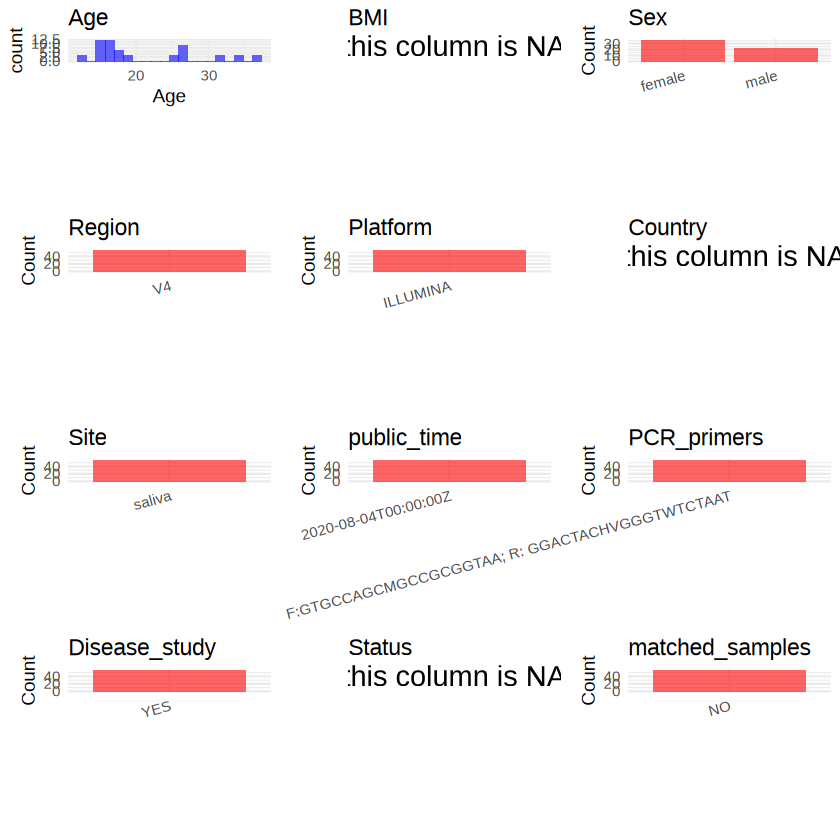

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA648248/metadata.csv", quote = T)